# 13 -- Score-Based Decision Strategy

Fraud decisions using ensemble score thresholds with SHAP-driven explanations per transaction.

## 1. Imports and Setup

In [57]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [58]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

sys.path.insert(0, '..')

import config
from src.rules import (
    assign_score_based_decisions,
    get_shap_top_feature,
    build_feature_lookup,
    evaluate_decisions,
    plot_decision_summary,
    plot_score_distribution_by_decision,
    plot_shap_by_decision,
)
from src.mrm import apply_uniform_score
from src.experiment import load_experiment_log

config.PLOTS_PATH.mkdir(parents=True, exist_ok=True)
config.RESULTS_PATH.mkdir(parents=True, exist_ok=True)

## 2. Load Data

In [59]:
X_test_selected = pd.read_parquet(config.RESULTS_PATH / 'X_test_selected.parquet')
y_test = pd.read_parquet(config.RESULTS_PATH / 'y_test.parquet').squeeze()
ensemble_test_proba = pd.read_parquet(config.RESULTS_PATH / 'ensemble_test_proba.parquet')

train_sorted = np.load(config.RESULTS_PATH / 'train_sorted.npy')

ensemble_score = apply_uniform_score(
    ensemble_test_proba.squeeze().values,
    train_sorted,
)

df = X_test_selected.copy()
df['isFraud'] = y_test.values
df['ensemble_proba'] = ensemble_test_proba.squeeze().values
df['ensemble_score'] = ensemble_score

print(f'shape: {df.shape}')
print(f'fraud rate: {df["isFraud"].mean():.4f}')
print(f'score range: {df["ensemble_score"].min()} -- {df["ensemble_score"].max()}')

shape: (88581, 118)
fraud rate: 0.0348
score range: 0 -- 999


## 3. Score Based Decision Strategy

In [60]:
df = assign_score_based_decisions(
    df,
    score_col='ensemble_score',
    approve_threshold=config.STRATEGY_APPROVE_THRESHOLD,
    decline_threshold=config.STRATEGY_DECLINE_THRESHOLD,
)

counts = df['decision'].value_counts()
pct = df['decision'].value_counts(normalize=True).round(4)

print('decision distribution:')
for d in ['DECLINE', 'STEP-UP', 'APPROVE']:
    if d in counts:
        print(f'  {d}: {counts[d]:,} ({pct[d]:.1%})')

decision distribution:
  DECLINE: 8,625 (9.7%)
  STEP-UP: 34,110 (38.5%)
  APPROVE: 45,846 (51.8%)


The decision strategy applies fixed thresholds to the ensemble score (0-1000 integer scale):

- **APPROVE**: score <= `config.STRATEGY_APPROVE_THRESHOLD` -- low risk, no friction
- **STEP-UP**: score between thresholds -- elevated risk, additional authentication
  required (OTP, 3DS challenge, or biometric verification)
- **DECLINE**: score > `config.STRATEGY_DECLINE_THRESHOLD` -- high risk, block transaction

Thresholds are configurable in config.py and would be calibrated by the fraud team based
on review capacity and risk appetite. The sensitivity analysis in Section 7 shows how
performance shifts across threshold configurations.

## 4. Decision Performance

In [61]:
eval_df = evaluate_decisions(df, config.TARGET, 'decision')
display(eval_df)

,decision,n_transactions,n_fraud,precision,pct_of_total_transactions,pct_of_total_fraud
0,DECLINE,8625,2104,0.2439,0.0974,0.6825
1,STEP-UP,34110,831,0.0244,0.3851,0.2695
2,APPROVE,45846,148,0.0032,0.5176,0.0480


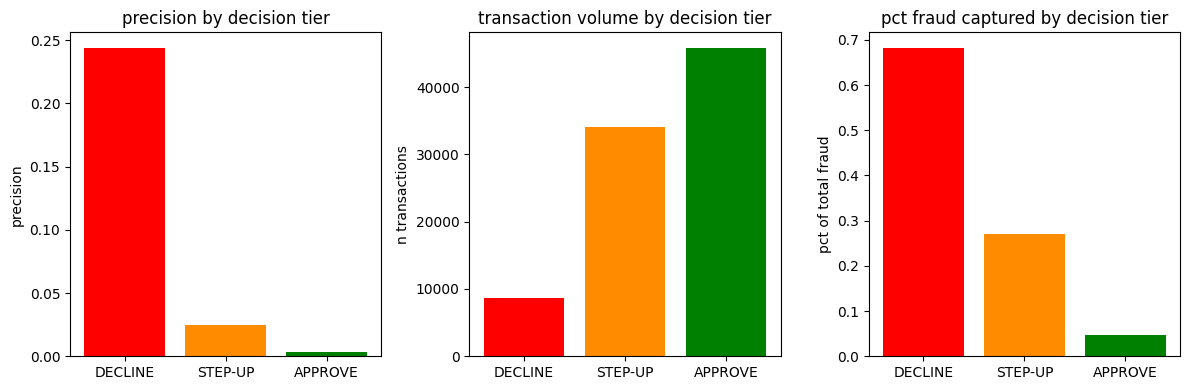

In [62]:
plot_decision_summary(
    eval_df,
    output_path=config.PLOTS_PATH / 'decision_summary.png',
)

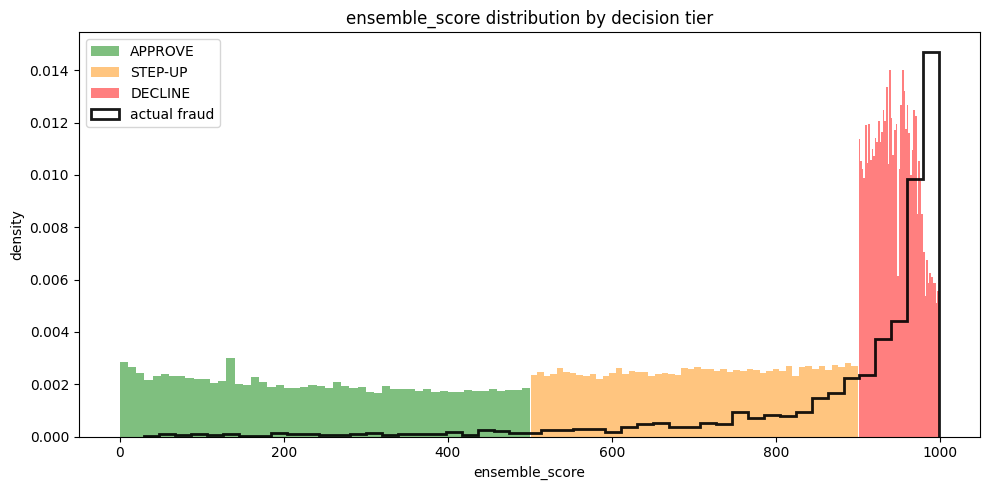

In [63]:
plot_score_distribution_by_decision(
    df,
    score_col='ensemble_score',
    decision_col='decision',
    target=config.TARGET,
    output_path=config.PLOTS_PATH / 'score_by_decision.png',
)

### Key findings

After running the cells above, check from `eval_df`:

- **DECLINE precision**: the fraction of DECLINE transactions that are actual fraud;
  high precision limits friction on legitimate customers
- **APPROVE precision**: should be close to the dataset base rate (~3.5%); if materially
  higher, lower `STRATEGY_APPROVE_THRESHOLD` in config.py
- **Fraud captured before APPROVE**: sum of `pct_of_total_fraud` for DECLINE + STEP-UP;
  this is the share of fraud caught before any transaction reaches the approve path
- **DECLINE false positive rate**: `1 - precision` in the DECLINE tier; shows what fraction
  of blocked transactions were legitimate

## 5. SHAP Explanations by Decision Tier

In [64]:
cat_final = joblib.load(config.OUTPUT_PATH / 'models' / 'catboost_final.pkl')
xgb_final = joblib.load(config.OUTPUT_PATH / 'models' / 'xgboost_final.pkl')
lgb_final = joblib.load(config.OUTPUT_PATH / 'models' / 'lightgbm_final.pkl')

# derive weights from experiment log
exp_log = load_experiment_log(config.RESULTS_PATH)
final_names = ['catboost_final', 'xgboost_final', 'lightgbm_final']
log_final = (exp_log[exp_log['model'].isin(final_names)]
             .drop_duplicates('model')
             .set_index('model'))

auc_vals = np.array([
    log_final.loc['catboost_final',  'metrics.val_auc'],
    log_final.loc['xgboost_final',   'metrics.val_auc'],
    log_final.loc['lightgbm_final',  'metrics.val_auc'],
])
raw_weights = auc_vals / auc_vals.sum()

weights = {
    'catboost_final':  float(raw_weights[0]),
    'xgboost_final':   float(raw_weights[1]),
    'lightgbm_final':  float(raw_weights[2]),
}
models = {
    'catboost_final':  cat_final,
    'xgboost_final':   xgb_final,
    'lightgbm_final':  lgb_final,
}

print('ensemble weights:')
for name, w in weights.items():
    print(f'  {name}: {w:.4f}')

ensemble weights:
  catboost_final: 0.3330
  xgboost_final: 0.3348
  lightgbm_final: 0.3322


In [65]:
# compute weighted ensemble shap values on 2000-row sample
X_sample = X_test_selected.sample(n=2000, random_state=42)

shap_values_weighted = None
for name, model in models.items():
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X_sample)
    if isinstance(sv, list):
        sv = sv[1]  # catboost binary: take positive class
    weight = weights[name]
    if shap_values_weighted is None:
        shap_values_weighted = weight * sv
    else:
        shap_values_weighted += weight * sv

print(f'shap_values shape: {shap_values_weighted.shape}')

shap_values shape: (2000, 115)


c:\Users\timot\fraud_model\fraud_model\fraud_env\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


In [66]:
feature_names = X_sample.columns.tolist()
lookup = build_feature_lookup(feature_names)

primary_drivers = get_shap_top_feature(
    shap_values_weighted, feature_names, lookup=lookup
)

# align sample rows with their decisions
df_sample = df.loc[X_sample.index].copy()
df_sample['primary_driver'] = primary_drivers.values

print(f'df_sample shape: {df_sample.shape}')
print(f'decision counts in sample:')
print(df_sample['decision'].value_counts().to_string())

df_sample shape: (2000, 120)
decision counts in sample:
decision
APPROVE    1016
STEP-UP     785
DECLINE     199


In [67]:
cols_display = ['decision', 'primary_driver']

for tier in ['DECLINE', 'STEP-UP', 'APPROVE']:
    subset = df_sample[df_sample['decision'] == tier]
    if subset.empty:
        print(f'{tier}: no transactions in sample')
        continue
    top5 = (subset['primary_driver']
            .value_counts()
            .head(5)
            .reset_index()
            .rename(columns={'index': 'feature', 'primary_driver': 'count'}))
    print(f'top 5 primary drivers -- {tier}:')
    display(top5)

top 5 primary drivers -- DECLINE:


,count,count
0,C13,82
1,C1,55
2,V281,11
3,transaction amount,9
4,card6 category,8


top 5 primary drivers -- STEP-UP:


,count,count
0,C1,218
1,C13,141
2,transaction amount,79
3,average TransactionAmt for P_emaildomain,48
4,C5,37


top 5 primary drivers -- APPROVE:


,count,count
0,C13,337
1,C1,103
2,D1,95
3,number of unique R_emaildomain for card1,84
4,average TransactionAmt for P_emaildomain,53


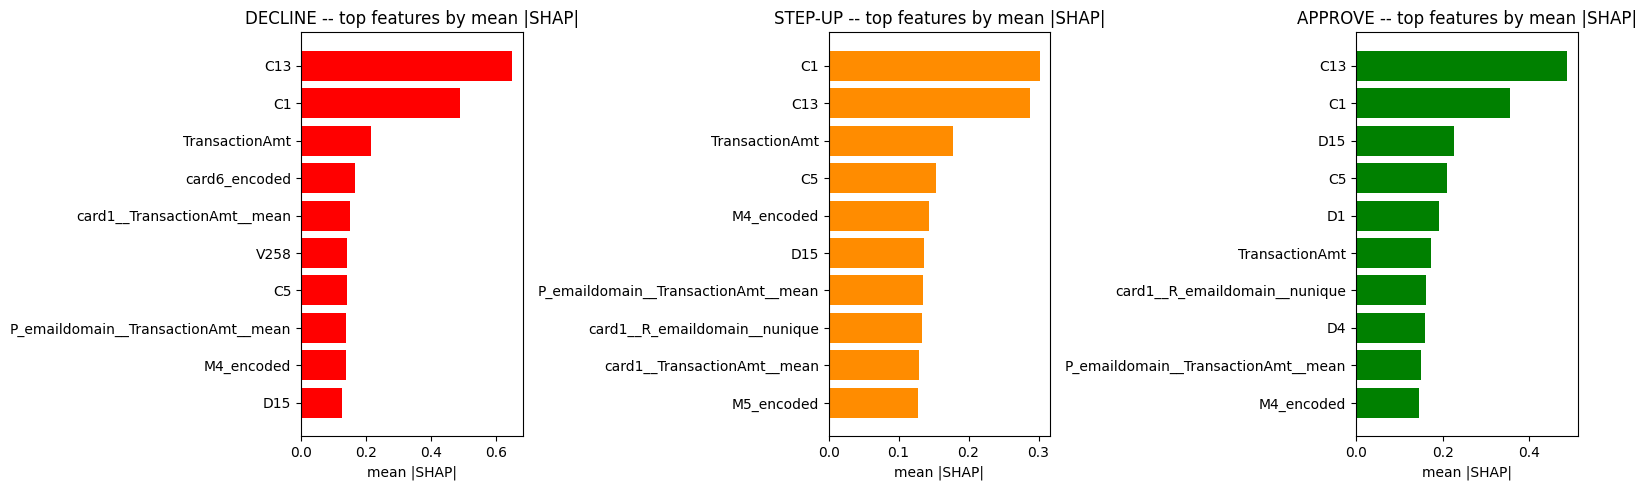

In [68]:
plot_shap_by_decision(
    shap_values_weighted,
    X_sample,
    df_sample['decision'],
    output_path=config.PLOTS_PATH / 'shap_by_decision.png',
)

SHAP values identify which features most influenced each individual transaction score.
The primary driver is the feature with the highest absolute SHAP value for that transaction.

This provides the explanation layer for the decision strategy: the score determines the
tier, SHAP explains why. In production this mapping enables per-transaction explanations
without re-running the full model -- the primary driver is computed once at score time
and stored alongside the decision.

## 6. Sample Decision Output

In [69]:
cols = ['ensemble_score', 'decision', 'primary_driver', 'isFraud']

for tier in ['DECLINE', 'STEP-UP', 'APPROVE']:
    subset = df_sample[df_sample['decision'] == tier][cols].head(10)
    print(f'--- {tier} ({len(df_sample[df_sample["decision"] == tier])} in sample) ---')
    display(subset)

--- DECLINE (199 in sample) ---


,ensemble_score,decision,primary_driver,isFraud
87258,921,DECLINE,C1,0
69919,979,DECLINE,C1,1
71866,932,DECLINE,C13,0
34923,971,DECLINE,C13,0
69485,960,DECLINE,C13,0
50545,948,DECLINE,V281,0
81274,936,DECLINE,C1,0
13810,903,DECLINE,C1,0
36569,964,DECLINE,V258,1
21079,943,DECLINE,C13,0


--- STEP-UP (785 in sample) ---


,ensemble_score,decision,primary_driver,isFraud
37468,601,STEP-UP,card2,0
84505,779,STEP-UP,C13,0
49195,764,STEP-UP,C5,0
54827,808,STEP-UP,C13,0
56663,685,STEP-UP,average TransactionAmt for P_emaildomain,0
62417,871,STEP-UP,C13,0
84484,582,STEP-UP,transaction amount,0
14784,825,STEP-UP,C1,0
44362,779,STEP-UP,V67,0
88032,687,STEP-UP,id 13,0


--- APPROVE (1016 in sample) ---


,ensemble_score,decision,primary_driver,isFraud
24134,335,APPROVE,C1,0
12635,248,APPROVE,number of unique R_emaildomain for card1,0
40468,217,APPROVE,D1,0
7340,247,APPROVE,C13,0
46781,256,APPROVE,C13,0
28100,84,APPROVE,D15,0
65261,93,APPROVE,average TransactionAmt for card1,0
58463,19,APPROVE,C13,0
52868,323,APPROVE,D1,0
65289,89,APPROVE,C13,0


In production, DECLINE and STEP-UP transactions are surfaced to the fraud analyst queue
with the primary driver visible alongside the score. Score and primary driver together
give the analyst context to make a final call or escalate without reviewing raw feature
values. APPROVE transactions bypass the queue entirely.

## 7. Threshold Sensitivity Analysis

In [72]:
threshold_configs = [
    {'name': 'conservative', 'approve': 300, 'decline': 600},
    {'name': 'default',      'approve': config.STRATEGY_APPROVE_THRESHOLD,
                             'decline': config.STRATEGY_DECLINE_THRESHOLD},
    {'name': 'aggressive',   'approve': 500, 'decline': 800},
    {'name': 'very aggressive',   'approve': 200, 'decline': 900},
]

rows = []
for cfg in threshold_configs:
    df_cfg = assign_score_based_decisions(
        df,
        score_col='ensemble_score',
        approve_threshold=cfg['approve'],
        decline_threshold=cfg['decline'],
    )
    eval_cfg = (evaluate_decisions(df_cfg, config.TARGET, 'decision')
                .set_index('decision'))

    def _get(tier, col, default=0.0):
        return float(eval_cfg.loc[tier, col]) if tier in eval_cfg.index else default

    pct_fraud_caught = _get('DECLINE', 'pct_of_total_fraud') + _get('STEP-UP', 'pct_of_total_fraud')

    rows.append({
        'config':            cfg['name'],
        'approve_thresh':    cfg['approve'],
        'decline_thresh':    cfg['decline'],
        'pct_declined':      round(_get('DECLINE', 'pct_of_total_transactions'), 4),
        'pct_stepup':        round(_get('STEP-UP',  'pct_of_total_transactions'), 4),
        'pct_approved':      round(_get('APPROVE',  'pct_of_total_transactions'), 4),
        'decline_precision': round(_get('DECLINE', 'precision'), 4),
        'stepup_precision':  round(_get('STEP-UP',  'precision'), 4),
        'pct_fraud_caught':  round(pct_fraud_caught, 4),
    })

sensitivity_df = pd.DataFrame(rows)
display(sensitivity_df)

,config,approve_thresh,decline_thresh,pct_declined,pct_stepup,pct_approved,decline_precision,stepup_precision,pct_fraud_caught
0,conservative,300,600,0.3908,0.2739,0.3353,0.0826,0.0064,0.9779
1,default,500,900,0.0974,0.3851,0.5176,0.2439,0.0244,0.9520
2,aggressive,500,800,0.1984,0.2840,0.5176,0.1446,0.0157,0.9520
3,very aggressive,200,900,0.0974,0.6661,0.2366,0.2439,0.0159,0.9864


Fraud teams use threshold sensitivity analysis to calibrate against operational constraints:

- **conservative** (approve=300, decline=600): wider STEP-UP band, more transactions
  require authentication; higher fraud capture at the cost of more friction
- **default**: balanced thresholds, calibrated on validation set performance
- **aggressive** (approve=500, decline=800): narrower STEP-UP band, fewer challenges;
  faster customer experience but lower total fraud capture

The choice depends on review capacity (how many STEP-UP transactions the team can
process), OTP/3DS cost, and the fraud team's risk appetite.

## 8. Final Summary

### Decision strategy overview

| Threshold | Value |
|-----------|-------|
| APPROVE threshold | `config.STRATEGY_APPROVE_THRESHOLD` |
| DECLINE threshold | `config.STRATEGY_DECLINE_THRESHOLD` |

### Performance at default thresholds

Check `eval_df` from Section 4 for exact values. Key metrics:

- **DECLINE**: precision and transaction volume from `eval_df`
- **STEP-UP**: precision and transaction volume from `eval_df`
- **APPROVE**: precision (should be close to base rate ~3.5%) and transaction volume
- **Total fraud caught before APPROVE**: sum of `pct_of_total_fraud` for DECLINE + STEP-UP

### Top fraud drivers from SHAP

Check the frequency tables in Section 5 for the top 3 features most commonly driving
DECLINE decisions. These are the features the ensemble most reliably uses to identify
high-risk transactions and should be prioritized in feature monitoring.

### Monitoring recommendations

- **Monthly**: review threshold calibration using the sensitivity analysis in Section 7;
  retrigger if business conditions (fraud volume, customer mix) shift materially
- **Weekly**: monitor precision per tier; flag if precision in any tier shifts by more
  than 5 percentage points from the baseline established at this run
- **On any score distribution shift (PSI > 0.1)**: re-evaluate thresholds before next
  deployment cycle (PSI tracked in Stage 11 MRM notebook)

### Production integration notes

- Thresholds configurable in config.py without code changes
- SHAP primary driver computed at score time and stored in the transaction record
- DECLINE and STEP-UP transactions surfaced to analyst queue with score and primary driver
- APPROVE transactions bypass review queue entirely